In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(os.getcwd())
print(os.listdir())

/home/alexander16/aequo-finance/data
['ps_data.csv', '01_btc_analysis.ipynb', '.ipynb_checkpoints', 'astronomical_analysis.ipynb', '__pycache__', 'data_feed.py', 'astronomical_data.ipynb', 'data_analysis_structure.txt']


In [4]:
from sqlalchemy import create_engine

engine = create_engine(os.getenv("EXOPLANET_DB_URL"))

In [5]:
#  star_systems table

star_systems_table = pd.read_csv("ps_data.csv",  comment="#", 
                              usecols=["hostname", "sy_snum", "sy_pnum", "st_teff", "st_rad", "st_mass",
                                       "st_logg", "sy_dist"])

# COLUMN hostname:       Host Name
# COLUMN sy_snum:        Number of Stars
# COLUMN sy_pnum:        Number of Planetsi io
# COLUMN st_teff:        Stellar Effective Temperature [K]
# COLUMN st_rad:         Stellar Radius [Solar Radius]
# COLUMN st_mass:        Stellar Mass [Solar mass]
# COLUMN st_logg:        Stellar Surface Gravity [log10(cm/s**2)]
# COLUMN sy_dist:        Distance [pc]


In [6]:
# exoplanets_data table

exoplanets_data_table = pd.read_csv("ps_data.csv", comment="#", 
                                    usecols=["pl_name", "default_flag", "discoverymethod", "disc_year",
                                             "pl_orbper", "pl_rade", "pl_bmasse", "pl_eqt", "rowupdate",
                                             "pl_pubdate", "hostname"])

# COLUMN pl_name:        Planet Name
# COLUMN default_flag:   Default Parameter Se
# COLUMN discoverymethod: Discovery Method
# COLUMN disc_year:      Discovery Year
# COLUMN pl_orbper:      Orbital Period [days]
# COLUMN pl_rade:        Planet Radius [Earth Radius]
# COLUMN pl_bmasse:      Planet Mass or Mass*sin(i) [Earth Mass]
# COLUMN pl_eqt:         Equilibrium Temperature [K]
# COLUMN rowupdate:      Date of Last Update
# COLUMN pl_pubdate:     Planetary Parameter Reference Publication Date
# COLUMN hostname:       Host Name

In [5]:
exoplanets_data_table.sample(5)

,pl_name,hostname,default_flag,discoverymethod,disc_year,pl_orbper,pl_rade,pl_bmasse,pl_eqt,rowupdate,pl_pubdate
7325,Kepler-1001 b,Kepler-1001,0,Transit,2016,14.305120,2.90900,NaN,NaN,2024-12-05,2018-12
36199,OGLE-TR-182 b,OGLE-TR-182,0,Transit,2007,3.979100,16.47723,340.078100,NaN,2019-03-18,2017-06
23297,Kepler-290 b,Kepler-290,0,Transit,2014,14.589368,NaN,NaN,NaN,2016-07-26,2016-07
7150,KOI-94 c,KOI-94,0,Transit,2013,10.423678,3.86400,6.204259,NaN,2024-02-21,2024-01
9421,Kepler-114 b,Kepler-114,0,Transit,2014,5.188489,NaN,NaN,NaN,2019-04-16,2019-03


In [7]:
star_systems_table.sample(5)

,hostname,sy_snum,sy_pnum,st_teff,st_rad,st_mass,st_logg,sy_dist
19504,Kepler-1955,1,1,5826.0,1.236,1.066,4.281,449.351
20885,Kepler-223,1,4,5697.0,1.639,NaN,NaN,1859.710
31320,Kepler-69,1,2,5700.0,0.991,0.914,4.399,730.625
25129,Kepler-341,1,4,6008.0,1.003,1.000,4.435,1047.030
39709,WASP-57,1,1,5600.0,0.836,0.954,4.574,398.276


In [12]:
import matplotlib.font_manager as fm 

fonts = sorted(set(fm.get_font_names()))

print(fonts)

['DejaVu Math TeX Gyre', 'DejaVu Sans', 'DejaVu Sans Condensed', 'DejaVu Sans Display', 'DejaVu Sans Light', 'DejaVu Sans Mono', 'DejaVu Serif', 'DejaVu Serif Condensed', 'DejaVu Serif Display', 'FontAwesome', 'FreeMono', 'FreeSans', 'FreeSerif', 'GLYPHICONS Halflings', 'Last Resort High-Efficiency', 'Liberation Mono', 'Liberation Sans', 'Liberation Sans Narrow', 'Liberation Serif', 'MathJax_AMS', 'MathJax_Caligraphic', 'MathJax_Fraktur', 'MathJax_Main', 'MathJax_Math', 'MathJax_SansSerif', 'MathJax_Script', 'MathJax_Size1', 'MathJax_Size2', 'MathJax_Size3', 'MathJax_Size4', 'MathJax_Typewriter', 'MathJax_Vector', 'MathJax_Vector-Bold', 'MathJax_WinChrome', 'MathJax_WinIE6', 'STIXGeneral', 'STIXNonUnicode', 'STIXSizeFiveSym', 'STIXSizeFourSym', 'STIXSizeOneSym', 'STIXSizeThreeSym', 'STIXSizeTwoSym', 'Ubuntu', 'Ubuntu Mono', 'Ubuntu Sans', 'Ubuntu Sans Mono', 'cmb10', 'cmex10', 'cmmi10', 'cmr10', 'cmss10', 'cmsy10', 'cmti10', 'cmtt10', 'dsrom10', 'esint10', 'eufm10', 'msam10', 'msbm10',

In [18]:
weights = sorted(set(fm.weight_dict))
print(weights)

['black', 'bold', 'book', 'demi', 'demibold', 'extra bold', 'heavy', 'light', 'medium', 'normal', 'regular', 'roman', 'semibold', 'ultralight']


In [23]:
import matplotlib.colors as mcolors

colors = sorted(set(mcolors.BASE_COLORS.keys())) + sorted(set(mcolors.CSS4_COLORS)) + sorted(set(mcolors.TABLEAU_COLORS))

print(colors)

['b', 'c', 'g', 'k', 'm', 'r', 'w', 'y', 'aliceblue', 'antiquewhite', 'aqua', 'aquamarine', 'azure', 'beige', 'bisque', 'black', 'blanchedalmond', 'blue', 'blueviolet', 'brown', 'burlywood', 'cadetblue', 'chartreuse', 'chocolate', 'coral', 'cornflowerblue', 'cornsilk', 'crimson', 'cyan', 'darkblue', 'darkcyan', 'darkgoldenrod', 'darkgray', 'darkgreen', 'darkgrey', 'darkkhaki', 'darkmagenta', 'darkolivegreen', 'darkorange', 'darkorchid', 'darkred', 'darksalmon', 'darkseagreen', 'darkslateblue', 'darkslategray', 'darkslategrey', 'darkturquoise', 'darkviolet', 'deeppink', 'deepskyblue', 'dimgray', 'dimgrey', 'dodgerblue', 'firebrick', 'floralwhite', 'forestgreen', 'fuchsia', 'gainsboro', 'ghostwhite', 'gold', 'goldenrod', 'gray', 'green', 'greenyellow', 'grey', 'honeydew', 'hotpink', 'indianred', 'indigo', 'ivory', 'khaki', 'lavender', 'lavenderblush', 'lawngreen', 'lemonchiffon', 'lightblue', 'lightcoral', 'lightcyan', 'lightgoldenrodyellow', 'lightgray', 'lightgreen', 'lightgrey', 'ligh

In [ ]:
#Average number of planets per star

avg_pl_per_star = pd.read_sql("""
    SELECT hostname, COUNT(*) AS exoplanets
    FROM exoplanets_data
    GROUP BY hostname
    ORDER BY ROUND(AVG(hostname))
""", engine)

avg_pl_per_star.plot.bar(x='hostname', y='exoplanets')

<Axes: xlabel='hostname'>

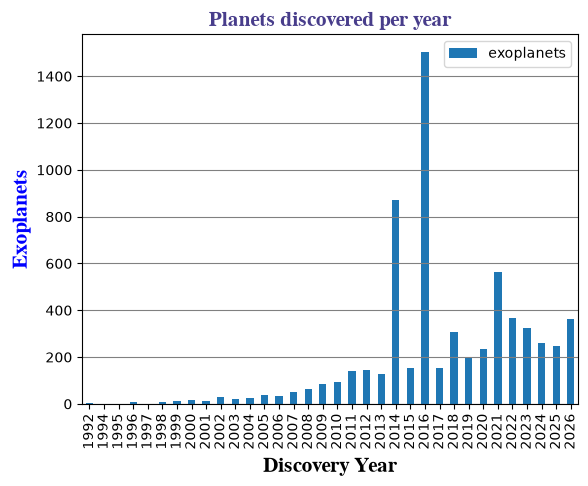

In [51]:
#Planets discovered per year

pl_disc_per_year = pd.read_sql("""
    SELECT disc_year, COUNT(*) AS exoplanets
    FROM exoplanets_data
    GROUP BY disc_year
    ORDER BY disc_year
""", engine)

pl_disc_per_year.plot.bar(x='disc_year', y='exoplanets')

plt.title('Planets discovered per year', fontsize=15, family='FreeSerif', fontweight='heavy',
          color="darkslateblue")

plt.xlabel('Discovery Year', fontsize=15, family='FreeSerif', fontweight='heavy',
           color='black')

plt.ylabel('Exoplanets', fontsize=15, family='FreeSerif', fontweight='extra bold',
           color='b')

plt.grid(axis='y',
         color='gray')

In [ ]:
#Planets similar to Earth

pl_similar_to_earth = pd.read_sql("""
    SELECT
""")

In [ ]:
#How often exoplanet records are updated

pl_records_avg_updates = pd.read_sql("""
    SELECT rowupdate, COUNT(*) AS exoplanets
    FROM exoplanets_data
    
    
""")

In [ ]:
#Oldest and most recent exoplanets discovered

old_new_pl_disc = pd.read_sql("""
    SELECT
""")

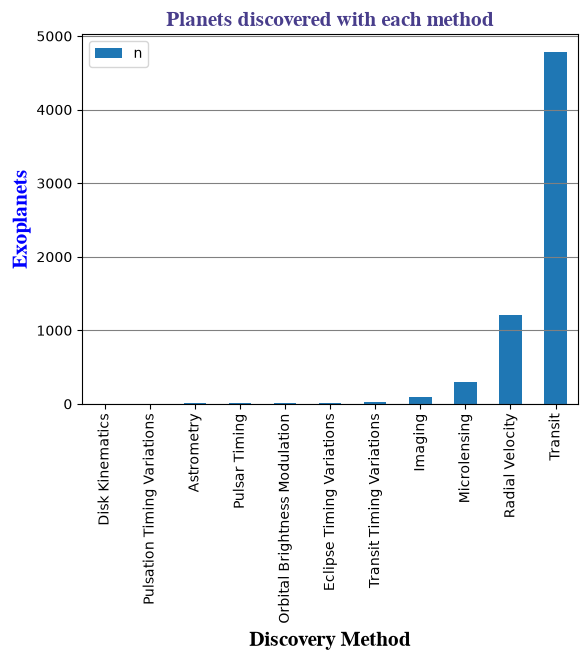

In [57]:
#Planets discovered with each method

pl_disc_per_discoverymethod = pd.read_sql("""
    SELECT discoverymethod, COUNT(*) AS n
    FROM exoplanets_data
    GROUP BY discoverymethod 
    ORDER BY n ASC

""", engine)

pl_disc_per_discoverymethod.plot.bar(x='discoverymethod', y='n')

plt.title('Planets discovered with each method', fontsize=15, family='FreeSerif', fontweight='heavy',
          color="darkslateblue")

plt.xlabel('Discovery Method', fontsize=15, family='FreeSerif', fontweight='heavy',
           color='black')

plt.ylabel('Exoplanets', fontsize=15, family='FreeSerif', fontweight='extra bold',
           color='b')

plt.grid(axis='y',
         color='gray')


In [ ]:
#planets per year for each method

pl_per_year_per_discoverymethod = pd.read_sql("""
    SELECT
""")